# 01 — Exploratory data analysis

**Owner:** Tech Lead · **Phase 2** · spec section 3.1

Questions this notebook answers, each ending in a modelling decision:

1. How imbalanced are the 38 classes? → metric and class weights
2. How many photos show the same leaf? → how we split
3. Are there duplicate images, inside or across splits? → cleaning
4. Are all images the same size and format? → preprocessing
5. Do classes differ in colour or background in ways a model could cheat with? → shortcut risk
6. How different are PlantDoc field photos? → why we test on them

**Run it on Colab** from the repo root, after `pip install -r requirements.txt` and `python data/download.py`.
Every number below is computed here; nothing is typed by hand. The test split is only *counted* (never modelled).

In [1]:
import hashlib, io, os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import Image as HFImage, load_from_disk
from IPython.display import Markdown, display
from PIL import Image

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
import sys
sys.path.insert(0, str(ROOT))
from src.data import check_no_leakage, compute_class_weights, load_split_tables
RAW = Path(os.environ.get("FROSTLEAF_RAW", ROOT / "data" / "raw"))
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
findings = []  # (finding, decision) pairs collected through the notebook

pv = load_from_disk(str(RAW / "plantvillage_color"))
print(pv)

DatasetDict({
    train: Dataset({
        features: ['image', 'image_path', 'label', 'crop', 'disease', 'leaf_id'],
        num_rows: 43596
    })
    test: Dataset({
        features: ['image', 'image_path', 'label', 'crop', 'disease', 'leaf_id'],
        num_rows: 10709
    })
})


In [2]:
# Identify the columns instead of assuming their names
split_names = list(pv.keys())
features = pv[split_names[0]].features
IMG = next(k for k, v in features.items() if isinstance(v, HFImage))
LABEL = next(k for k, v in features.items() if hasattr(v, "names"))
LEAF = "leaf_id" if "leaf_id" in features else None
CLASSES = features[LABEL].names
print(f"splits={split_names}  image={IMG!r}  label={LABEL!r}  leaf={LEAF!r}  classes={len(CLASSES)}")
assert LEAF is not None, "no leaf_id column: we cannot split by leaf; stop and tell the Data Engineer"

meta = pd.concat(
    [pv[s].select_columns([LABEL, LEAF]).to_pandas().assign(split=s) for s in split_names],
    ignore_index=True,
)
meta["cls"] = meta[LABEL].map(lambda i: CLASSES[i])
meta["crop"] = meta["cls"].str.split("___").str[0]
meta["healthy"] = meta["cls"].str.contains("healthy")
print(meta.groupby("split").size().rename("images").to_string())

splits=['train', 'test']  image='image'  label='label'  leaf='leaf_id'  classes=38


split
test     10709
train    43596


## 1. Class distribution

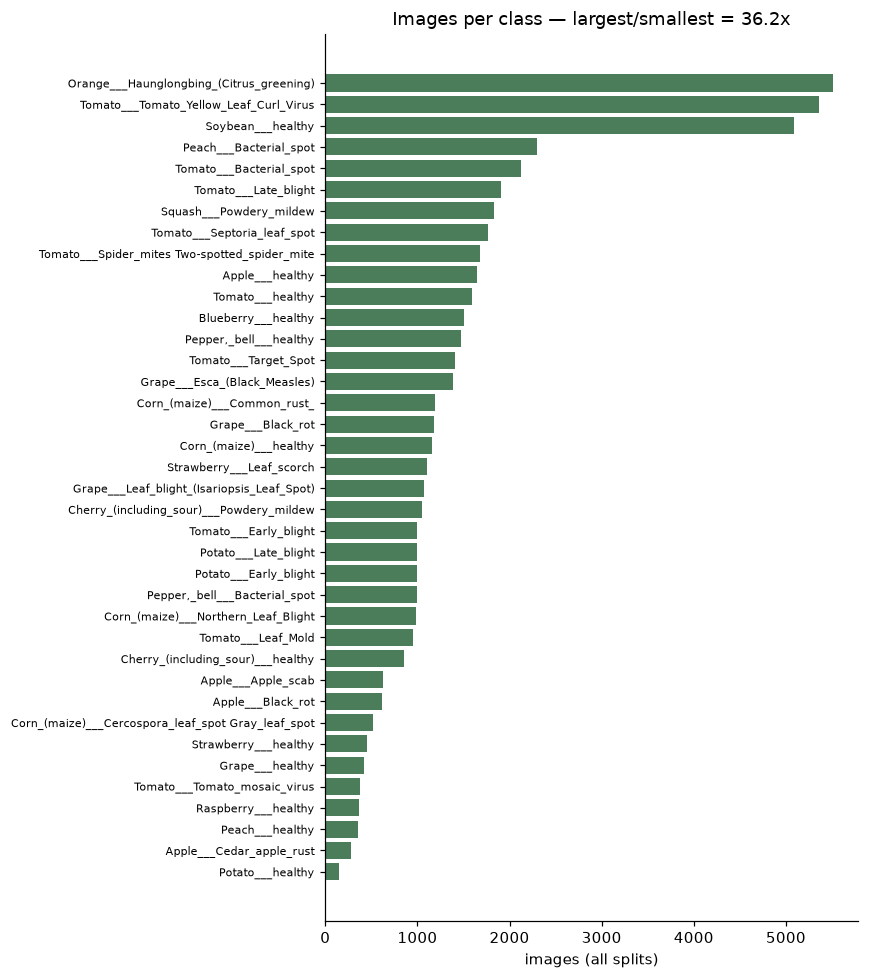

Smallest: Potato___healthy (152), largest: Orange___Haunglongbing_(Citrus_greening) (5507)
Classes under 500 images: 7 of 38


In [3]:
counts = meta.groupby(["cls", "split"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total")
ratio = counts["total"].max() / counts["total"].min()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(counts.index, counts["total"], color="#4C7D5B")
ax.set_xlabel("images (all splits)")
ax.set_title(f"Images per class — largest/smallest = {ratio:.1f}x")
ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "class_distribution.png"); plt.show()

small = counts.index[0]; big = counts.index[-1]
print(f"Smallest: {small} ({counts['total'].iloc[0]}), largest: {big} ({counts['total'].iloc[-1]})")
print(f"Classes under 500 images: {(counts['total'] < 500).sum()} of {len(counts)}")
findings.append((
    f"Classes range from {counts['total'].min():,} to {counts['total'].max():,} images ({ratio:.1f}x imbalance)",
    "Primary metric macro-F1 (not accuracy); balanced class weights; report per-class recall",
))

In [4]:
# Is the official train/test split stratified? (share of each class per split)
share = counts.drop(columns="total").div(counts.drop(columns="total").sum(axis=0), axis=1)
drift = (share.max(axis=1) - share.min(axis=1)).max()
print(f"Largest difference in a class's share between splits: {drift:.2%}")
print("-> official split is close to stratified" if drift < 0.01 else "-> class shares differ between splits; stratify our validation split")

Largest difference in a class's share between splits: 1.23%
-> class shares differ between splits; stratify our validation split


## 2. Photos per leaf (leakage risk)

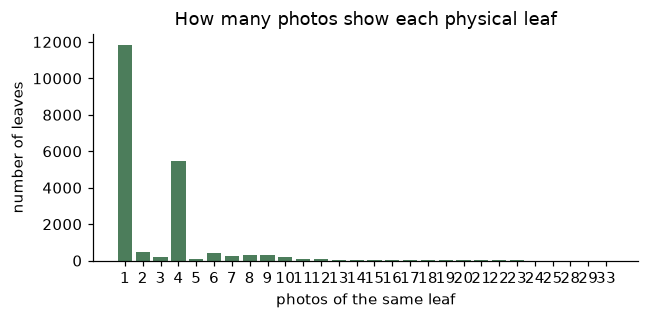

20,015 leaves; 8,181 have >1 photo, covering 42,471 images (78.2%); max photos of one leaf = 33
Leaves that appear in more than one official split: 227
Leaves labelled with more than one class: 0


In [5]:
per_leaf = meta.groupby(LEAF).size()
dist = per_leaf.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(dist.index.astype(str), dist.values, color="#4C7D5B")
ax.set_xlabel("photos of the same leaf"); ax.set_ylabel("number of leaves")
ax.set_title("How many photos show each physical leaf")
fig.tight_layout(); fig.savefig(FIG / "photos_per_leaf.png"); plt.show()

multi = (per_leaf > 1).sum()
imgs_in_multi = per_leaf[per_leaf > 1].sum()
print(f"{len(per_leaf):,} leaves; {multi:,} have >1 photo, covering {imgs_in_multi:,} images "
      f"({imgs_in_multi / len(meta):.1%}); max photos of one leaf = {per_leaf.max()}")

leaf_splits = meta.groupby(LEAF)["split"].nunique()
crossing = (leaf_splits > 1).sum()
print(f"Leaves that appear in more than one official split: {crossing}")
leaf_classes = meta.groupby(LEAF)["cls"].nunique()
print(f"Leaves labelled with more than one class: {(leaf_classes > 1).sum()}")
findings.append((
    f"{imgs_in_multi / len(meta):.1%} of images share their leaf with another photo (up to {per_leaf.max()} per leaf); "
    f"{crossing} leaves cross the official splits",
    "Split by leaf_id (StratifiedGroupKFold) and assert no leaf_id is in two splits",
))

## 3. Duplicate images

In [6]:
def image_bytes(item):
    """Raw encoded bytes of one image record (decode=False)."""
    if item.get("bytes"):
        return item["bytes"]
    return Path(item["path"]).read_bytes()

rows = []
for s in split_names:
    raw = pv[s].cast_column(IMG, HFImage(decode=False))
    for i, item in enumerate(raw[IMG]):
        b = image_bytes(item)
        with Image.open(io.BytesIO(b)) as im:
            rows.append((s, i, hashlib.md5(b).hexdigest(), im.size[0], im.size[1], im.mode, len(b)))
files = pd.DataFrame(rows, columns=["split", "idx", "md5", "w", "h", "mode", "nbytes"])
files = files.merge(meta.reset_index(drop=True)[["cls", LEAF]], left_index=True, right_index=True)

dup_groups = files.groupby("md5").filter(lambda g: len(g) > 1)
n_groups = dup_groups["md5"].nunique()
cross_split = dup_groups.groupby("md5")["split"].nunique().gt(1).sum()
cross_class = dup_groups.groupby("md5")["cls"].nunique().gt(1).sum()
print(f"Exact-duplicate groups: {n_groups} ({len(dup_groups)} images)")
print(f"  ...spanning two splits: {cross_split}; with conflicting labels: {cross_class}")
findings.append((
    f"{n_groups} groups of byte-identical images ({cross_split} across splits, {cross_class} with conflicting labels)",
    "Keep one copy per group, in the split of its leaf; drop conflicting-label groups; check_no_leakage also compares hashes"
    if n_groups else "No duplicates: no cleaning needed, but check_no_leakage still compares hashes",
))

Exact-duplicate groups: 21 (42 images)
  ...spanning two splits: 5; with conflicting labels: 0


## 4. Image size and format

In [7]:
sizes = files.groupby(["w", "h", "mode"]).size().rename("images").reset_index()
display(sizes)
odd = files[(files["w"] != 256) | (files["h"] != 256) | (files["mode"] != "RGB")]
print(f"Images that are not 256x256 RGB: {len(odd)}")
print(f"File size: median {files['nbytes'].median() / 1024:.0f} KB, max {files['nbytes'].max() / 1024:.0f} KB")
findings.append((
    "All images are 256x256 RGB" if odd.empty else f"{len(odd)} images are not 256x256 RGB",
    "Resize to the config image_size (224, or 160 if Colab timing requires) and scale pixels to [0, 1] in one shared preprocess()",
))

,w,h,mode,images
0,256,256,RGB,54304
1,256,256,RGBA,1


Images that are not 256x256 RGB: 1
File size: median 16 KB, max 119 KB


## 5. Sample images and look-alike classes

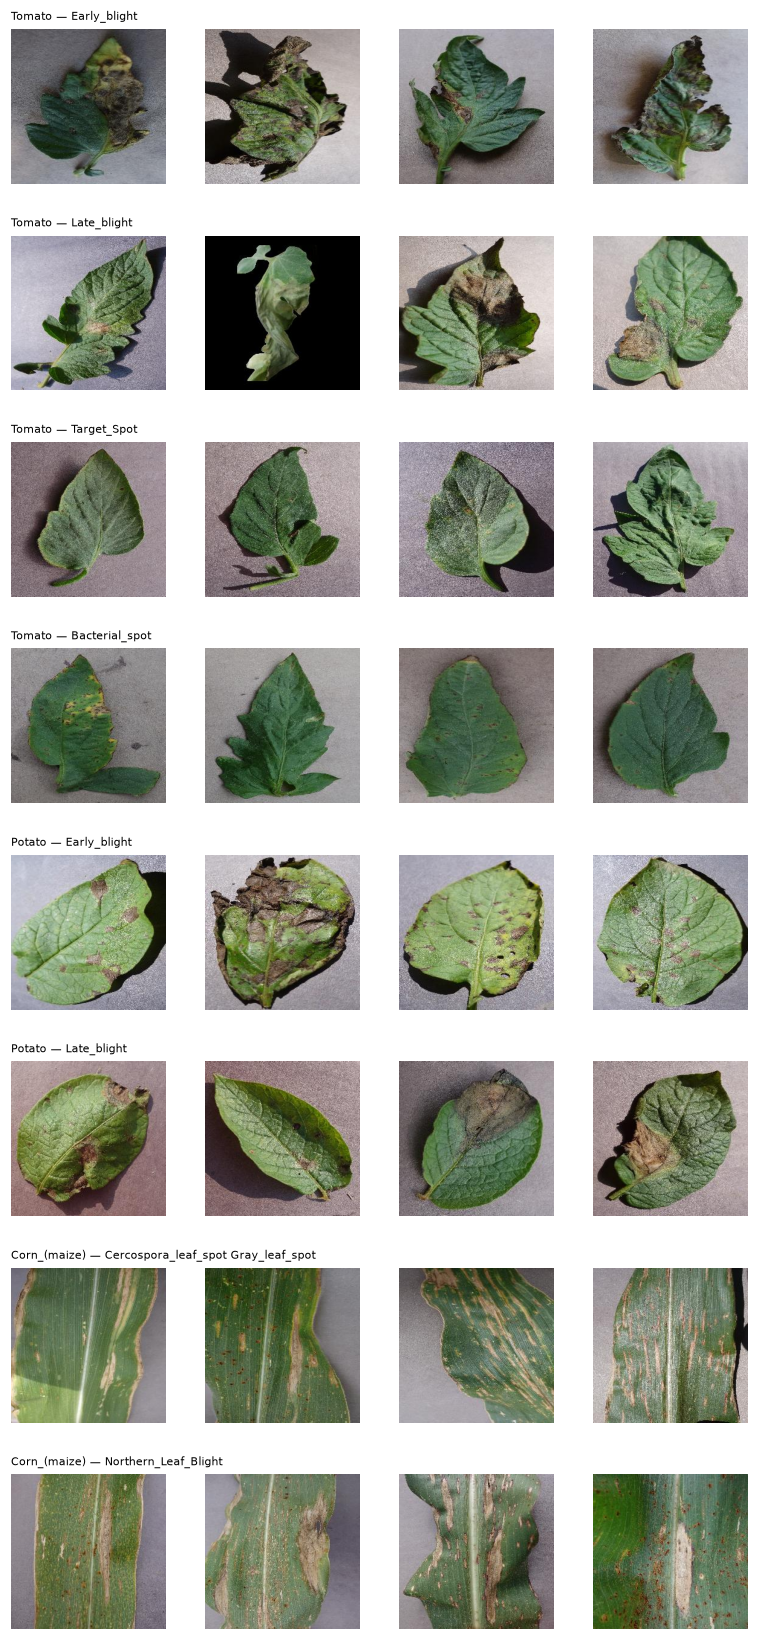

Look-alike pairs differ only in lesion shape and colour: expect most confusions inside a crop.


In [8]:
LOOKALIKES = [
    "Tomato___Early_blight", "Tomato___Late_blight", "Tomato___Target_Spot", "Tomato___Bacterial_spot",
    "Potato___Early_blight", "Potato___Late_blight",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot", "Corn_(maize)___Northern_Leaf_Blight",
]
show = [c for c in LOOKALIKES if c in CLASSES] or CLASSES[:8]
train = pv[split_names[0]]
labels_arr = np.array(train[LABEL])
rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(show), 4, figsize=(7, 1.9 * len(show)))
for r, c in enumerate(show):
    idx = rng.choice(np.flatnonzero(labels_arr == CLASSES.index(c)), size=4, replace=False)
    for k, j in enumerate(idx):
        ax = axes[r, k]; ax.imshow(train[int(j)][IMG]); ax.axis("off")
    axes[r, 0].set_title(c.replace("___", " — "), fontsize=7, loc="left")
fig.tight_layout(); fig.savefig(FIG / "lookalike_samples.png"); plt.show()
print("Look-alike pairs differ only in lesion shape and colour: expect most confusions inside a crop.")
findings.append((
    "Diseases of the same crop look alike (e.g. tomato early vs late blight)",
    "Error analysis groups confusions by crop; at least two augmentations (flip, rotation) that keep lesion shape",
))

## 6. Colour and background (shortcut risk)

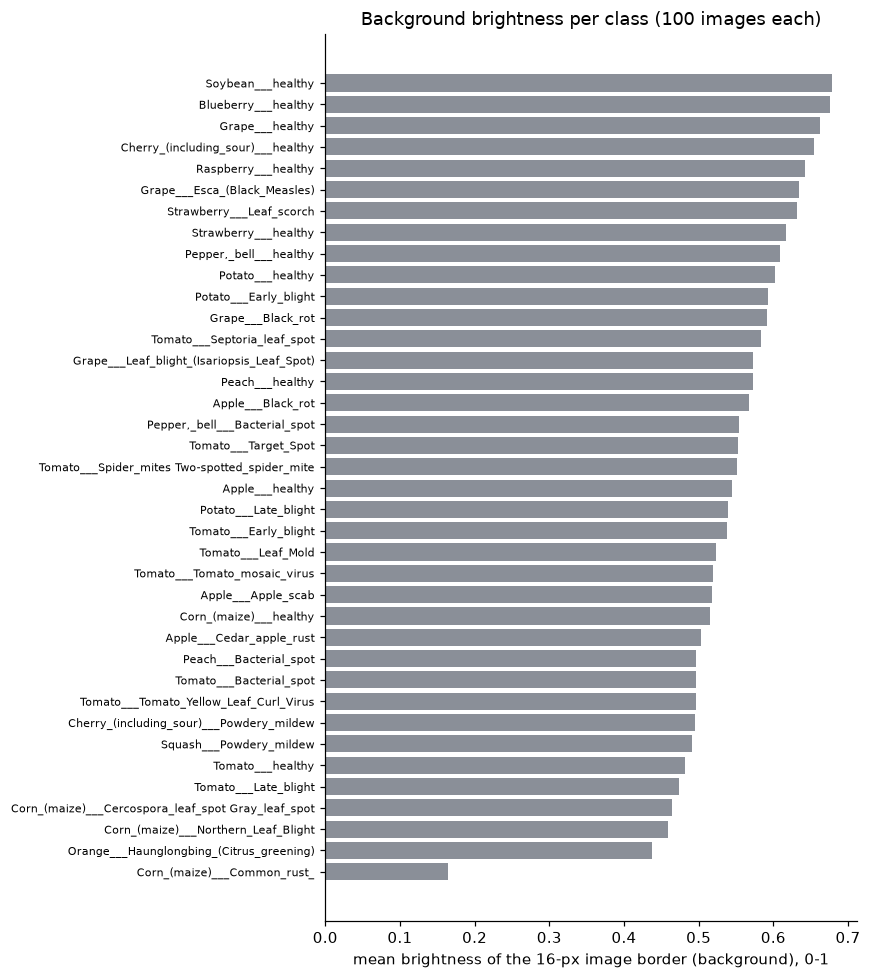

Background brightness spans 0.16-0.68 across classes (spread 0.51)


In [9]:
def mean_rgb(img):
    a = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
    border = np.concatenate([a[:16].reshape(-1, 3), a[-16:].reshape(-1, 3),
                             a[:, :16].reshape(-1, 3), a[:, -16:].reshape(-1, 3)])
    return a.reshape(-1, 3).mean(0), border.mean()

stats = []
for c in CLASSES:
    idx = np.flatnonzero(labels_arr == CLASSES.index(c))
    for j in rng.choice(idx, size=min(100, idx.size), replace=False):
        rgb, border = mean_rgb(train[int(j)][IMG])
        stats.append((c, *rgb, border))
colour = pd.DataFrame(stats, columns=["cls", "R", "G", "B", "border"]).groupby("cls").mean()

fig, ax = plt.subplots(figsize=(8, 9))
order = colour["border"].sort_values().index
ax.barh(order, colour.loc[order, "border"], color="#8A8F98")
ax.set_xlabel("mean brightness of the 16-px image border (background), 0-1")
ax.set_title("Background brightness per class (100 images each)")
ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "background_brightness.png"); plt.show()

spread = colour["border"].max() - colour["border"].min()
print(f"Background brightness spans {colour['border'].min():.2f}-{colour['border'].max():.2f} across classes (spread {spread:.2f})")
findings.append((
    f"Background brightness differs by up to {spread:.2f} (0-1 scale) between classes",
    "Possible shortcut: compare colour vs segmented PlantVillage in an ablation, and test on PlantDoc"
    if spread > 0.1 else "Backgrounds are similar across classes; shortcut risk from brightness is low, still tested on PlantDoc",
))

## 7. PlantDoc: the field-photo test set

In [10]:
pd_root = RAW / "plantdoc"
cmap = pd.read_csv(ROOT / "data" / "plantdoc_class_map.csv")
excl = set(pd.read_csv(ROOT / "data" / "plantdoc_exclude.csv")["path"])
rows = []
for _, m in cmap.iterrows():
    for part in ("train", "test"):
        folder = pd_root / part / m["plantdoc_class"]
        if folder.is_dir():
            for f in folder.iterdir():
                rel = f"{part}/{m['plantdoc_class']}/{f.name}"
                rows.append((m["plantvillage_class"], rel, rel in excl))
pdoc = pd.DataFrame(rows, columns=["pv_class", "path", "excluded"])
kept = pdoc[~pdoc["excluded"]].groupby("pv_class").size().reindex(cmap["plantvillage_class"], fill_value=0)
print(f"PlantDoc mapped images: {len(pdoc):,}; excluded: {pdoc['excluded'].sum():,}; kept: {(~pdoc['excluded']).sum():,}")
print(f"Classes with fewer than 20 kept images: {(kept < 20).sum()} of {len(kept)}")
display(kept.sort_values().rename("kept images").to_frame().head(10))
findings.append((
    f"PlantDoc gives {(~pdoc['excluded']).sum():,} usable field photos over {(kept > 0).sum()} classes; "
    f"{(kept < 20).sum()} classes have under 20",
    "Report PlantDoc macro-F1 over present classes only, with per-class support; treat small classes as indicative",
))

PlantDoc mapped images: 2,578; excluded: 392; kept: 2,186
Classes with fewer than 20 kept images: 1 of 28


,kept images
plantvillage_class,
Tomato___Spider_mites Two-spotted_spider_mite,0
Apple___healthy,44
Tomato___Tomato_mosaic_virus,50
Peach___healthy,50
Soybean___healthy,51
Grape___Black_rot,55
Cherry_(including_sour)___healthy,56
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,58
Tomato___healthy,58


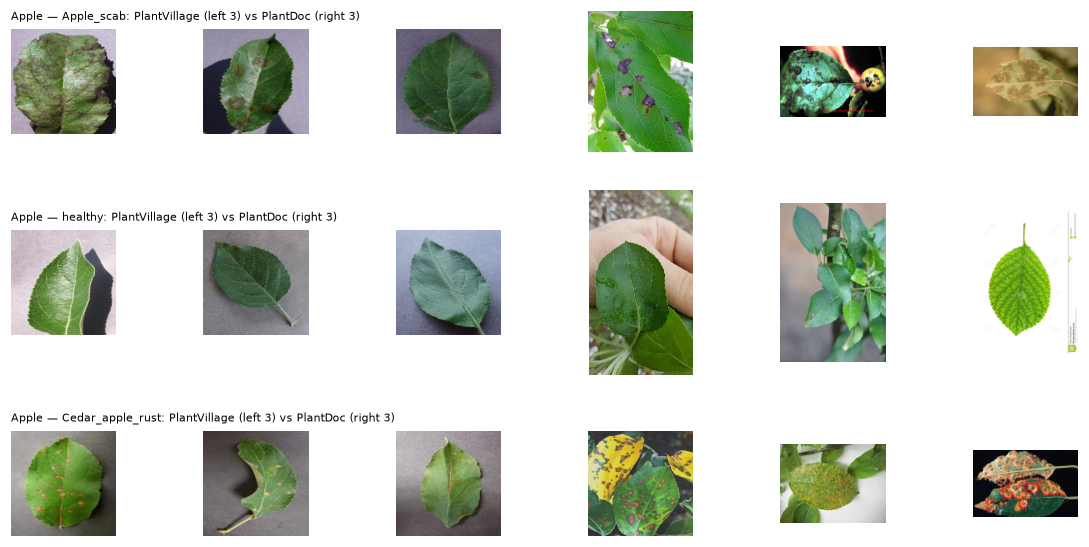

PlantDoc photos have natural backgrounds, several leaves and varied lighting: the domain gap our secondary hypothesis measures.


In [11]:
pairs = [c for c in cmap["plantvillage_class"] if kept.get(c, 0) >= 3][:3]
fig, axes = plt.subplots(len(pairs), 6, figsize=(10, 1.9 * len(pairs)), squeeze=False)
for r, c in enumerate(pairs):
    pv_idx = rng.choice(np.flatnonzero(labels_arr == CLASSES.index(c)), size=3, replace=False)
    doc = pdoc[(pdoc["pv_class"] == c) & ~pdoc["excluded"]].sample(3, random_state=42)["path"]
    imgs = [train[int(j)][IMG] for j in pv_idx] + [Image.open(pd_root / p).convert("RGB") for p in doc]
    for k, im in enumerate(imgs):
        axes[r, k].imshow(im); axes[r, k].axis("off")
    axes[r, 0].set_title(f"{c.replace('___', ' — ')}: PlantVillage (left 3) vs PlantDoc (right 3)", fontsize=7, loc="left")
fig.tight_layout(); fig.savefig(FIG / "plantvillage_vs_plantdoc.png"); plt.show()
print("PlantDoc photos have natural backgrounds, several leaves and varied lighting: the domain gap our secondary hypothesis measures.")

## 8. Missing values

In [ ]:
missing = meta[[LABEL, LEAF]].isna().sum()
empty = int((files["nbytes"] == 0).sum())
fallback = int(meta[LEAF].astype(str).str.startswith("fallback_").sum())
print(f"Missing labels: {missing[LABEL]}, missing leaf IDs: {missing[LEAF]}, empty image files: {empty}")
print(f"Leaf IDs filled with a per-image fallback (no entry in the source leaf map): {fallback:,} ({fallback / len(meta):.1%})")
findings.append((
    f"No missing labels or empty files; {fallback / len(meta):.1%} of images have no leaf ID in the source and get a per-image fallback ID",
    "No imputation needed; fallback images are treated as their own leaf, and the file-hash check still guards against duplicates crossing splits",
))

## 9. The split we train on (`src.data`)

In [ ]:
tables = load_split_tables()
check_no_leakage(tables["train"], tables["val"], tables["test"])
split_counts = pd.DataFrame({k: t["label"].value_counts() for k, t in tables.items()}).fillna(0).astype(int)
print({k: len(t) for k, t in tables.items()}, "- no leaf_id or file hash shared between splits")
train_counts = split_counts["train"]
weights = compute_class_weights(tables["train"]["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy())
print(f"Train imbalance: {train_counts.max():,} / {train_counts.min():,} = {train_counts.max() / train_counts.min():.1f}x; "
      f"balanced class weights from {min(weights.values()):.2f} to {max(weights.values()):.2f}")
display(split_counts.sort_values("train").head(5))
findings.append((
    f"Final leak-free split: {len(tables['train']):,} / {len(tables['val']):,} / {len(tables['test']):,} images; "
    f"train imbalance {train_counts.max() / train_counts.min():.1f}x",
    "Class weights computed on train only; macro-F1 for model selection on validation; test used once",
))

## 10. One sample image per class

In [ ]:
cols = 8
rows_n = int(np.ceil(len(CLASSES) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(14, 2.1 * rows_n))
for ax in axes.ravel():
    ax.axis("off")
for k, c in enumerate(CLASSES):
    j = int(rng.choice(np.flatnonzero(labels_arr == k)))
    ax = axes.ravel()[k]
    ax.imshow(train[j][IMG])
    ax.set_title(c.replace("___", "\n"), fontsize=6)
fig.tight_layout(); fig.savefig(FIG / "samples_per_class.png"); plt.show()
print("Every class is a single, centred leaf on a plain background: very different from PlantDoc field photos.")

## Findings → decisions

In [12]:
table = "| # | Finding | Modelling decision |\n|---|---|---|\n" + "\n".join(
    f"| {i} | {f} | {d} |" for i, (f, d) in enumerate(findings, 1))
display(Markdown(table))
(FIG / "findings.md").write_text(table + "\n")

| # | Finding | Modelling decision |
|---|---|---|
| 1 | Classes range from 152 to 5,507 images (36.2x imbalance) | Primary metric macro-F1 (not accuracy); balanced class weights; report per-class recall |
| 2 | 78.2% of images share their leaf with another photo (up to 33 per leaf); 227 leaves cross the official splits | Split by leaf_id (StratifiedGroupKFold) and assert no leaf_id is in two splits |
| 3 | 21 groups of byte-identical images (5 across splits, 0 with conflicting labels) | Keep one copy per group, in the split of its leaf; drop conflicting-label groups; check_no_leakage also compares hashes |
| 4 | 1 images are not 256x256 RGB | Resize to the config image_size (224, or 160 if Colab timing requires) and scale pixels to [0, 1] in one shared preprocess() |
| 5 | Diseases of the same crop look alike (e.g. tomato early vs late blight) | Error analysis groups confusions by crop; at least two augmentations (flip, rotation) that keep lesion shape |
| 6 | Background brightness differs by up to 0.51 (0-1 scale) between classes | Possible shortcut: compare colour vs segmented PlantVillage in an ablation, and test on PlantDoc |
| 7 | PlantDoc gives 2,186 usable field photos over 27 classes; 1 classes have under 20 | Report PlantDoc macro-F1 over present classes only, with per-class support; treat small classes as indicative |

1351

**Before committing:** run every cell on the real data, read each printed conclusion, and fix any decision the numbers do not support. Commit the notebook *with outputs* plus `notebooks/figures/`.